# Momentum portfolio: monthly, daily and weekly rebalancing and initial risk positioning

This analysis compares a frozen stock portfolio with mechanical monthly, daily and weekly rebalancing over 1 May?3 August 2026. Starting equity is **USD 500 million**. Fund X is a daily-rebalanced proxy comprising 20% S&P GSCI (`^SPGSCI`), 50% URTH and 30% BNDW.

The 2026 period has already been explored during research. Results are **historical adjusted-close diagnostics**. Trading, borrowing, collateral, and data conventions are stated below.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, SVG
from rebalancing.data_access import load_config, load_training
from rebalancing.policies import freeze_policy, verify_freeze
from rebalancing.risk_model import diagnostics
out = Path('aligned_method/rebalancing')
config = load_config()
training = load_training(config)
policy = freeze_policy(config, training)
assert verify_freeze(policy)
assert training.index.max() <= pd.Timestamp('2026-04-28')
print(f'Training: {training.index.min().date()} to {training.index.max().date()}, {len(training)-1} returns')
print('Evaluation:', len(policy['session_dates']), 'closes and', len(policy['session_dates'])-1, 'return intervals')
print('Monthly fill dates:', policy['rebalance_dates'])
print('Block length:', policy['block_length'], '|', policy['block_length_rule'])

Training: 2024-04-29 to 2026-04-28, 500 returns
Evaluation: 64 closes and 63 return intervals
Monthly fill dates: ['2026-06-01', '2026-07-01']
Block length: 13 | 1 + largest lag with abs(ACF) > 1.96/sqrt(n) in portfolio returns or squared returns, lags 1..20; cap 21


## Initial portfolio and risk

The portfolio retains the existing eight long and four short stock positions. Gross exposure is 100%, split 80% long and 20% short. The Ledoit?Wolf covariance, benchmark sensitivities, concentration, and stress diagnostics use observations through 28 April 2026 exclusively. P2 and P3 scale every weight by one frozen factor toward cash when a justified volatility budget is configured. Their default status is unconfigured.

In [2]:
holdings = pd.read_csv('aligned_method/validated_strategy/initial_portfolio.csv', index_col=0)
display(holdings)
display(diagnostics(training, pd.Series(policy['weights']), policy['sectors']))

,Weight,Sector,Position ($m),Expected annual return
WDC,0.075375,Tech,37.687341,0.139597
MU,0.050000,Tech,25.000000,0.133950
EQNR,0.150000,Energy,75.000000,0.132067
CAT,0.150000,Industrials,75.000000,0.126487
MRNA,0.074625,Healthcare,37.312659,0.125210
CNQ,0.150000,Energy,75.000000,0.124336
VLO,0.100000,Energy,50.000000,0.123664
HAL,0.050000,Energy,25.000000,0.121714
RXRX,-0.050000,Healthcare,-25.000000,-0.015361
ZS,-0.050000,Tech,-25.000000,-0.014958


,metric,value
0,lw_volatility,0.180698
1,gross_exposure,1.000000
2,net_exposure,0.600000
3,long_exposure,0.800000
4,short_exposure,0.200000
5,holding_hhi,0.103750
6,max_holding_gross,0.150000
7,sector_hhi,0.303750
8,sector_gross:Energy,0.450000
9,sector_gross:Healthcare,0.174625


## Reproducible computation

Run the next cell to rebuild all 10,000 joint contiguous-block scenarios, freeze the policy before historical price access, replay the configured strategies, and write the audit artifacts. Each strategy receives identical sampled market histories. All subsequent order quantities use preceding-close NAV and prices, then fill at the next scheduled adjusted close. Initial entry is an idealized same-close allocation.

The shared ledger charges 10 basis points of actual traded notional and an illustrative 2% annual borrow fee on prior-close short market value, using elapsed calendar days/365. It tracks restricted short collateral and rejects unavailable financing. Adjusted-price returns include dividend effects in signed synthetic units.

In [3]:
from run_rebalancing import main
results = main()

Frozen policy before simulation and evaluation price access


Completed 1000/10000 paired bootstrap scenarios


Completed 2000/10000 paired bootstrap scenarios


Completed 3000/10000 paired bootstrap scenarios


Completed 4000/10000 paired bootstrap scenarios


...

Completed 8000/10000 paired bootstrap scenarios


Completed 9000/10000 paired bootstrap scenarios


Completed 10000/10000 paired bootstrap scenarios


strategy                                                         status  net_return  max_drawdown  realized_volatility  gross_return  mtm_net_return  excess_return  tracking_error  turnover  transaction_cost  terminal_liquidation_cost   borrow_cost  simulation_percentile
      B0                                                proxy benchmark    0.002294     -0.045120             0.077475      0.002294        0.002294            NaN             NaN       NaN               NaN                        NaN           NaN                  20.04
      P0                              historical close-price diagnostic    0.042756     -0.089073             0.286604      0.045894        0.043841       0.040462        0.251930  2.039668      5.000000e+05              542624.233847 526100.776027                  41.01
      P1                              historical close-price diagnostic    0.078810     -0.063309             0.255826      0.082282        0.079894       0.076516        0.226919  2.2

Completed research artifacts: C:\Users\lcy20\OneDrive\文件\Past Paper\Der Pricing\Projects\GMC\gmc-momentum-strategy\aligned_method\rebalancing


## Historical outcomes and simulation comparison

Net return includes hypothetical terminal liquidation costs. Daily NAV remains marked to market. Fund X is an index calculation with daily component rebalancing and no assumed execution costs. Stock contributions, order quantities, fills, fees, and collateral balances are saved separately.

,strategy,status,net_return,max_drawdown,realized_volatility,gross_return,mtm_net_return,excess_return,tracking_error,turnover,transaction_cost,terminal_liquidation_cost,borrow_cost,simulation_percentile
0,B0,proxy benchmark,0.002294,-0.045120,0.077475,0.002294,0.002294,NaN,NaN,NaN,NaN,NaN,NaN,20.04
1,P0,historical close-price diagnostic,0.042756,-0.089073,0.286604,0.045894,0.043841,0.040462,0.251930,2.039668,5.000000e+05,542624.233847,526100.776027,41.01
2,P1,historical close-price diagnostic,0.078810,-0.063309,0.255826,0.082282,0.079894,0.076516,0.226919,2.259007,6.347527e+05,542034.741420,522616.349748,53.45
3,P2,unconfigured: initial risk budget required,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,P3,unconfigured: initial risk budget required,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,P4,historical close-price diagnostic,0.046399,-0.067090,0.257000,0.051318,0.047471,0.044105,0.227955,3.677831,1.366194e+06,535723.031274,539566.486642,42.86
6,P5,historical close-price diagnostic,0.050779,-0.068785,0.258414,0.054752,0.051845,0.048485,0.228979,2.772027,8.983095e+05,532754.877307,535772.266816,44.14
7,P6,unconfigured: dynamic risk budget required,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,P7,unconfigured: drawdown threshold and reduction...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


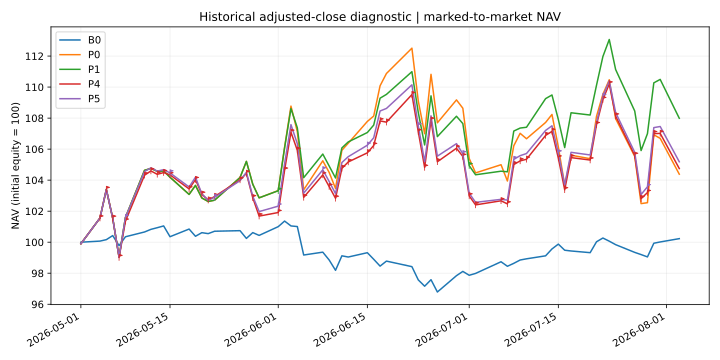

,strategy,status,scenarios,failed_scenarios,mean_net_return,median_net_return,p05_net_return,p95_net_return,mean_excess_return,outperformance_frequency,loss_frequency,worst_5pct_mean_return,mean_max_drawdown,p05_max_drawdown,p95_max_drawdown,mean_turnover,mean_transaction_cost,mean_terminal_liquidation_cost,mean_borrow_cost,statistics_basis
0,B0,configured,10000.0,0.0,0.033684,0.035342,-0.035172,0.096218,0.000000,0.0000,0.1862,-0.056331,-0.036078,-0.086904,-0.012567,0.000000,0.000000e+00,NaN,0.000000,all scenarios
1,P0,configured,10000.0,0.0,0.075519,0.071375,-0.108123,0.279991,0.041835,0.6268,0.2712,-0.148028,-0.081017,-0.162530,-0.031408,1.995280,5.000000e+05,535235.533631,509642.697065,all scenarios
2,P1,configured,10000.0,0.0,0.073200,0.068518,-0.107349,0.271599,0.039515,0.6197,0.2724,-0.148294,-0.080398,-0.161810,-0.030797,2.166441,5.875890e+05,535724.991525,524962.191517,all scenarios
3,P2,unconfigured: initial risk budget required,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,P3,unconfigured: initial risk budget required,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,P4,configured,10000.0,0.0,0.072689,0.067905,-0.108210,0.271420,0.039005,0.6154,0.2720,-0.148472,-0.080324,-0.161433,-0.030562,3.055880,1.047133e+06,536851.757930,532601.972140,all scenarios
6,P5,configured,10000.0,0.0,0.072803,0.068165,-0.108000,0.270697,0.039119,0.6172,0.2705,-0.148788,-0.080299,-0.162273,-0.030637,2.489964,7.541595e+05,536937.837131,531164.010936,all scenarios
7,P6,unconfigured: dynamic risk budget required,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,P7,unconfigured: drawdown threshold and reduction...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,comparison,status,paired_scenarios,mean_difference,median_difference,p05_difference,p95_difference,positive_difference_frequency
0,rebalancing,configured,10000.0,-0.002320,-0.001497,-0.021523,0.013952,0.4309
1,initial risk,unconfigured: initial risk budget required,NaN,NaN,NaN,NaN,NaN,NaN
2,risk portfolio rebalancing,unconfigured: initial risk budget required,NaN,NaN,NaN,NaN,NaN,NaN
3,daily rebalancing,configured,10000.0,-0.002830,-0.001713,-0.026535,0.017224,0.4302
4,weekly rebalancing,configured,10000.0,-0.002716,-0.001389,-0.026481,0.016917,0.4427
5,risk-triggered reduction,unconfigured: dynamic risk budget required,NaN,NaN,NaN,NaN,NaN,NaN
6,loss-triggered reduction,unconfigured: drawdown threshold and reduction...,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
display(pd.read_csv(out/'actual_metrics.csv'))
display(SVG(filename=str(out/'figures/historical_nav.svg')))
display(pd.read_csv(out/'simulation_summary.csv'))
display(pd.read_csv(out/'paired_comparisons.csv'))

The outperformance frequency is the proportion of scenarios outperforming Fund X under the specified historical sample and simulation assumptions. Historical resampling does not establish that momentum predicts future excess returns. All nine predefined strategy IDs are reported, including unconfigured risk variants.

In [5]:
display(pd.read_csv(out/'baseline_reconciliation.csv'))
display(pd.read_csv(out/'attribution.csv'))
display(Markdown((out/'data_quality_report.md').read_text(encoding='utf-8')))
manifest = json.loads((out/'run_manifest.json').read_text(encoding='utf-8'))
print('Policy hash:', manifest['policy_sha256'])
print('Scenario index hash:', manifest['sample_indices_sha256'])
print('Dependencies:', manifest['dependencies'])

,measure,published,standardized
0,gross_return,0.045894,0.045894
1,net_liquidation_return,0.042808,0.042756


,ticker,gross_stock_pnl,stock_pnl,transaction_cost,borrow_cost,net_pnl,liquidation_cost,liquidation_pnl,strategy
0,WDC,8.370086e+06,8.370086e+06,37687.341018,0.000000,8.332399e+06,46057.427146,8.286341e+06,P0
1,MU,1.325213e+07,1.325213e+07,25000.000000,0.000000,1.322713e+07,38252.131819,1.318888e+07,P0
2,EQNR,1.148923e+06,1.148923e+06,75000.000000,0.000000,1.073923e+06,76148.923092,9.977742e+05,P0
3,CAT,-4.897895e+06,-4.897895e+06,75000.000000,0.000000,-4.972895e+06,70102.104821,-5.042997e+06,P0
4,MRNA,8.034928e+06,8.034928e+06,37312.658982,0.000000,7.997616e+06,45347.587435,7.952268e+06,P0
5,CNQ,-1.667722e+05,-1.667722e+05,75000.000000,0.000000,-2.417722e+05,74833.227797,-3.166054e+05,P0
6,VLO,1.282565e+07,1.282565e+07,50000.000000,0.000000,1.277565e+07,62825.649297,1.271282e+07,P0
7,HAL,-5.781524e+06,-5.781524e+06,25000.000000,0.000000,-5.806524e+06,19218.476068,-5.825742e+06,P0
8,RXRX,1.548673e+06,1.548673e+06,25000.000000,124411.035822,1.399262e+06,23451.327200,1.375810e+06,P0
9,ZS,-2.619628e+06,-2.619628e+06,25000.000000,133054.254738,-2.777683e+06,27619.628319,-2.805302e+06,P0


# Data quality and execution assumptions

- The original stock training data is derived from synthetic_prices.csv. Its provenance, survivorship coverage, and corporate-action conventions remain independently unverified.

- The cached evaluation prices were downloaded by the original analysis with yfinance auto_adjust=True. Stock, URTH, and BNDW levels therefore represent dividend/split-adjusted return proxies. Exact cached corporate-action adjustments have not been independently reconciled. https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html

- ^SPGSCI is the S&P GSCI price/spot index series; the separate total-return series is ^SPGSCITR. It omits the total-return variant collateral yield. Fund X mixes this price index with ETF adjusted-return proxies and is not an independently verified tradable fund. https://finance.yahoo.com/quote/%5ESPGSCI/ ; https://finance.yahoo.com/quote/%5ESPGSCITR/

- Opening fills, action-level dividends, split events, halts, delistings, and borrow availability are unavailable in the cached evaluation panel. Adjusted-close synthetic-unit accounting includes short dividend effects through signed adjusted returns; separate dividend cash flows are not added.

- The initial allocation uses fractional synthetic units; subsequent monthly quantity changes are rounded to the nearest whole synthetic unit. These adjusted units cannot be interpreted as exchange-executable shares.

- Missing or nonpositive prices cause a hard failure. No backfilling or assumed missing-price fills occur. Insufficient collateral cash or nonpositive NAV rejects a scenario and is explicitly counted.

- Benchmark pre-cutoff adjusted prices were fetched separately from Yahoo Finance and are archived with hashes. The joint panel combines this source with the original stock training panel. Source revisions and convention differences can affect the result.

- The initial risk budget is unconfigured by default. P2/P3 remain visible as unconfigured relaxed-exposure variants. Dynamic volatility and drawdown triggers P6/P7 also require explicit thresholds and responses. Their supported engines are exercised by tests; configured production strategies are reported consistently.

- Daily and five-session policies use previous-close information. Evolving EWMA risk is estimated from each path independently with pre-cutoff covariance initialization; the 0.94 decay is a declared assumption. Price and risk bands summarize pointwise scenario distributions.

- The 2026 evaluation period has been explored before this implementation. This is a historical diagnostic comparison, with illustrative costs and financing constraints.

Policy hash: 281f359a1803a142a2fe92b7d44ac4554c73aab5015544e91028ab9a7fd2195b
Scenario index hash: 5202c77c93a4cae6222d4c0ea6341406d0cf68f7644c1faa0467e88c8578a24e
Dependencies: {'numpy': '2.4.4', 'pandas': '3.0.3', 'scikit-learn': '1.9.1', 'exchange-calendars': '4.13.2', 'matplotlib': '3.10.9', 'nbformat': '5.11.0', 'nbclient': '0.11.0'}


## Joint asset price and evolving risk paths

Each of the 10,000 scenarios contains aligned prices for all 12 stocks and all three benchmark components. Risk starts from the pre-cutoff Ledoit?Wolf covariance and updates after each completed return using an exponentially weighted second moment with declared decay 0.94. Each path maintains its own prices, risk estimate, holdings, cash, and drawdown.

P4 restores original targets daily. P5 restores them every five observed sessions: observations 1?5 support the order filled at observation 6. Orders at observation t use information through t?1; terminal liquidation takes precedence. P6 supports ratcheted volatility-budget exposure reduction, and P7 supports a one-time drawdown-triggered exposure reduction with no re-entry. Their thresholds remain visibly unconfigured until justified independently.

The shaded bands are pointwise 5th?95th percentiles, with median curves and predefined example paths 0?4. They summarize scenarios; the boundaries are not complete price paths. Portfolio NAV plots show marked-to-market values.

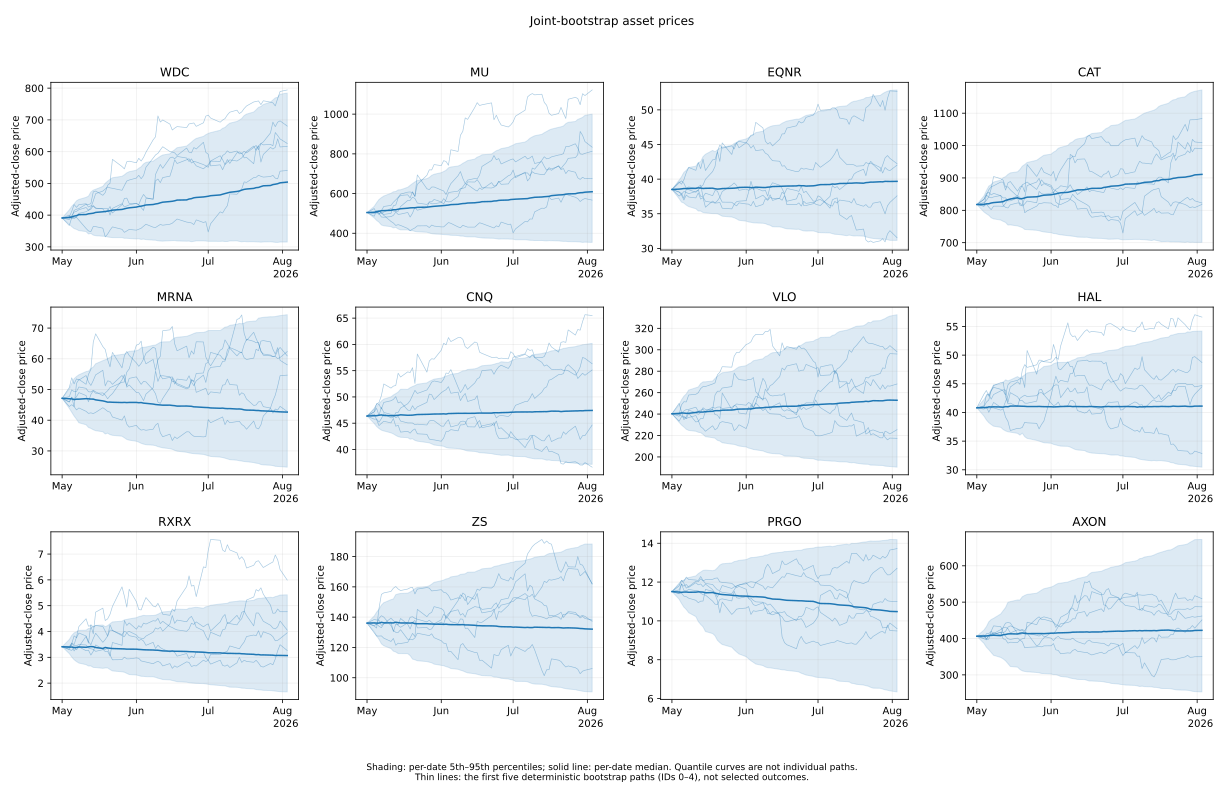

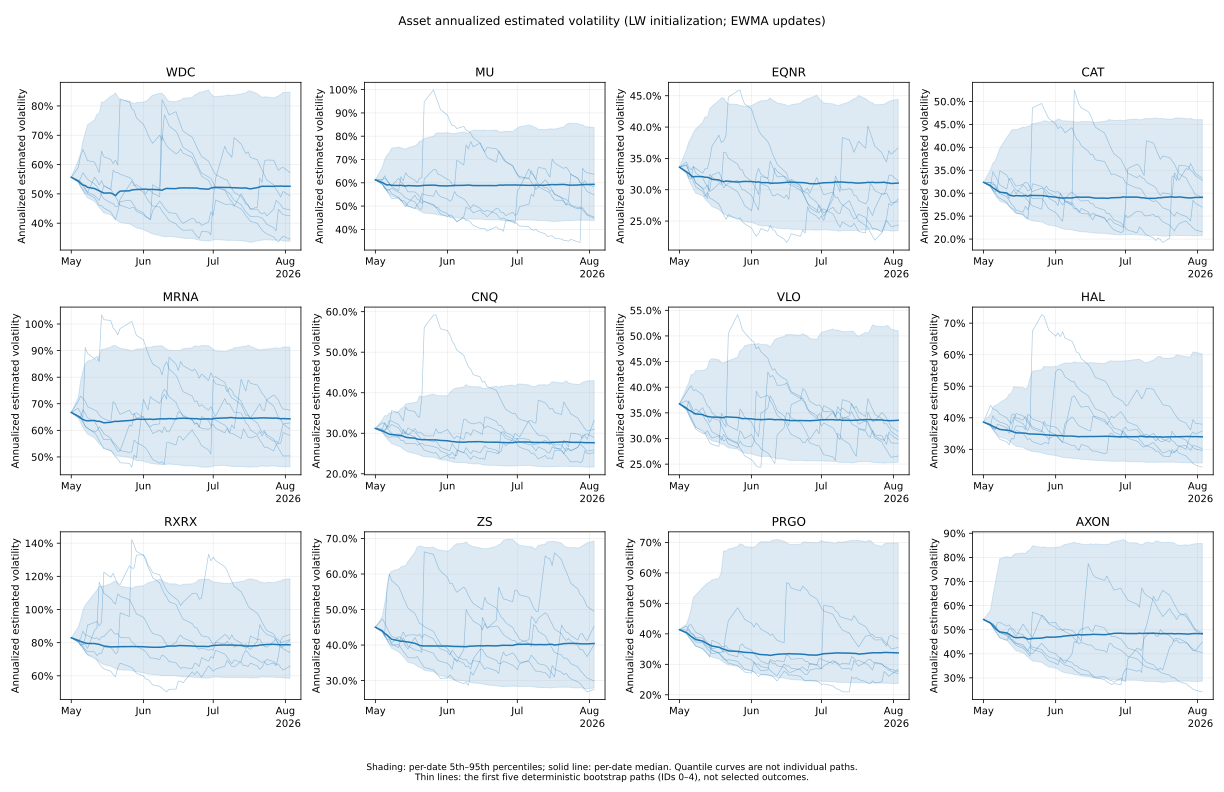

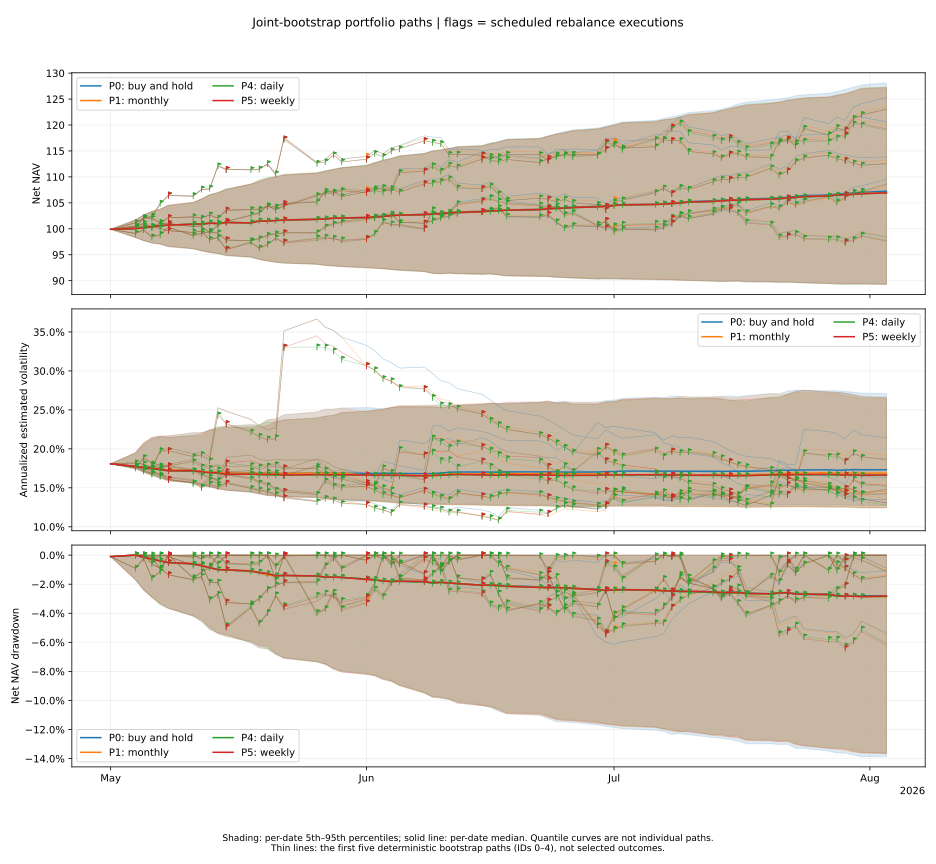

,date,strategy,metric,q05,q50,q95,failed_scenarios
0,2026-05-01,P0,nav,99.900002,99.900002,99.900002,0
1,2026-05-01,P0,volatility,0.180879,0.180879,0.180879,0
2,2026-05-01,P0,drawdown,-0.001000,-0.001000,-0.001000,0
3,2026-05-04,P0,nav,98.315224,100.042313,101.707146,0
4,2026-05-04,P0,volatility,0.174599,0.177349,0.194872,0
5,2026-05-04,P0,drawdown,-0.016848,0.000000,0.000000,0
6,2026-05-05,P0,nav,97.728317,100.175995,102.645264,0
7,2026-05-05,P0,volatility,0.170258,0.176119,0.207326,0
8,2026-05-05,P0,drawdown,-0.023903,-0.001479,0.000000,0


,date,ledger,volatility,drawdown,weights,covariance,strategy
0,2026-05-01,net,0.180879,-0.001000,[ 0.07545013 0.05005005 0.15015015 0.150150...,[[ 3.09929565e-01 2.29819771e-01 2.59864739e...,P0
1,2026-05-04,net,0.188063,0.000000,[ 0.07608343 0.05234242 0.15368849 0.145228...,[[ 0.30087519 0.24001605 0.01784229 0.07997...,P0
2,2026-05-05,net,0.197291,0.000000,[ 0.07859347 0.05709319 0.15109082 0.147496...,[[ 3.23342843e-01 3.12177603e-01 1.75294997e...,P0
3,2026-05-06,net,0.203148,-0.017932,[ 0.08310576 0.06053211 0.1414628 0.153898...,[[ 3.26297550e-01 3.17412661e-01 -3.03313358e...,P0
4,2026-05-07,net,0.221801,-0.042211,[ 0.08181905 0.06020803 0.14077694 0.152481...,[[ 0.33069682 0.31639712 -0.01077912 0.12378...,P0


In [6]:
for name in ['asset_price_simulation', 'asset_risk_simulation', 'portfolio_simulation']:
    display(SVG(filename=str(out/'figures'/f'{name}.svg')))
display(pd.read_csv(out/'simulation_path_quantiles.csv').head(9))
display(pd.read_csv(out/'risk_history.csv').head())

## Interpretation and limits

Monthly rebalancing isolates the effect of restoring frozen targets after weight drift. Initial risk reduction is a separately configurable policy. Both decisions must be fixed using pre-cutoff information.

The source stock history has unverified provenance. The cached adjusted closes support an idealized return diagnostic. Verified opening fills, raw corporate actions, short availability, margin requirements, and market impact at this scale require additional data. P2/P3 require an independently justified initial risk budget; P6/P7 require explicit dynamic risk or drawdown thresholds and responses. The original published baseline and notebooks remain available separately.

The detailed report, run manifest, simulation samples, accounting ledgers, and warnings are saved under `aligned_method/rebalancing/`.

??????????????????????????????????????????????????????????????????????????? 10,000 ????????